# What caused the accuracy drop? Ablation, decision and full run

**LIAR-Triage, notebook 3**

Notebook 2 ended with a puzzle. v2 eliminated empty replies, cut anachronisms and used about a third of
the output tokens, but it got *more* verdicts wrong: 2 claims fixed vs 11 broken across 93 paired
claims (p ≈ 0.02).

The problem: v2 changed **three things at once** (the prompt, JSON mode and reasoning effort), so we
can't tell which change caused the drop. This notebook changes **one thing at a time**. That method is
called an *ablation*.

**The runs (all on the same 50 development claims):**

| Run | Prompt | JSON mode | Reasoning effort | "Unverifiable" allowed | Compare with | Isolates |
|---|---|---|---|---|---|---|
| v1 (done) | v1 | off | default | no | — | baseline |
| v2 (done) | v2 | on | **low** | no | — | — |
| **A: `v2_default`** | v2 | on | **default** | no | v2 | reasoning effort (v2 prompt) |
| **B: `v1_low`** | v1 | off | **low** | no | v1 | reasoning effort (v1 prompt) |
| **C: `v3`** | v2 + abstain | on | low | **yes** | v2 | abstention |

**Decision rule, written before seeing the results:**
> Among the runs with a failure rate of 5% or less, choose the one with the highest **binary macro-F1**
> (abstentions count as wrong). If two are within 0.02 of each other, choose the one that uses fewer tokens.

Macro-F1 is used rather than accuracy because the model's bias toward "false" can make plain accuracy
look better than it is. Writing the rule down first stops us choosing whichever number looks best afterwards.

**How to use:** keep this notebook in the project folder and choose **Run All**. Earlier results are reused.

## Setup

In [1]:
%pip install -q openai python-dotenv pydantic pandas matplotlib

import importlib
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

import pipeline, evaluate as ev
importlib.reload(pipeline); importlib.reload(ev)

pd.set_option("display.max_colwidth", 140)
pd.set_option("display.width", 200)

PROVIDER = "groq"
RUN_ABLATIONS = True   # Part 1: about 150 calls, roughly 15-20 minutes on the free tier
FULL_RUN = True       # Part 3: about 1,200 calls, roughly 2+ hours. Turn on when ready.
WORKERS = 1

for f in ["pipeline.py", "evaluate.py", ".env", "data/test.tsv",
          pipeline.results_path(PROVIDER, "v1"), pipeline.results_path(PROVIDER, "v2")]:
    print(("OK      " if Path(f).exists() else "MISSING ") + str(f))


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.
OK      pipeline.py
OK      evaluate.py
OK      .env
OK      data/test.tsv
OK      results\groq_openai-gpt-oss-20b.jsonl
OK      results\groq_openai-gpt-oss-20b_v2.jsonl


---
## Part 1: run the ablations

In [2]:
ABLATIONS = ["v2_default", "v1_low", "v3"]
if RUN_ABLATIONS:
    for v in ABLATIONS:
        pipeline.run(provider=PROVIDER, limit=50, workers=WORKERS, version=v)

[v2_default] 50 cached, 0 to process with openai/gpt-oss-20b
Done. Results in results\groq_openai-gpt-oss-20b_v2_default.jsonl
[v1_low] 152 cached, 0 to process with openai/gpt-oss-20b
Done. Results in results\groq_openai-gpt-oss-20b_v1_low.jsonl
[v3] 116 cached, 0 to process with openai/gpt-oss-20b
Done. Results in results\groq_openai-gpt-oss-20b_v3.jsonl


> If a run shows every claim as `api_error`, the provider rejected a setting. Inspect it with
> `ev.load_results(pipeline.results_path(PROVIDER, "v1_low"))["error"].iloc[0]`.

---
## Part 2: results

In [3]:
RUNS = ["v1", "v1_low", "v2", "v2_default", "v3"]
dfs, flats = {}, {}
for v in RUNS:
    path = pipeline.results_path(PROVIDER, v)
    if path.exists():
        dfs[v] = ev.load_results(path)
        flats[v] = ev.flatten_ok(dfs[v])
    else:
        print("not run yet:", v)

def tokens(df):
    c = df["completion_tokens"].dropna()
    return float(c.median()) if len(c) else float("nan")

table = pd.DataFrame({v: {**ev.health(dfs[v]), "median output tokens": tokens(dfs[v]), **ev.metrics(flats[v])}
                      for v in dfs})
table

C:\Users\Emma\Documents\self\RESEARCH PROJECTS\llm-misinfo-triage\evaluate.py:102: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  toks = (df["prompt_tokens"].fillna(0) + df["completion_tokens"].fillna(0))


,v1,v1_low,v2,v2_default,v3
claims,50.000,152.000,133.000,50.000,124.000
usable answers,45.000,152.000,49.000,45.000,116.000
failure rate,0.100,0.000,0.632,0.100,0.065
empty replies,5.000,0.000,0.000,5.000,0.000
rate-limited claims,13.000,102.000,0.000,2.000,88.000
median latency (s),4.840,4.690,5.020,5.100,24.225
mean tokens per call,NaN,465.000,774.000,1142.000,818.000
median output tokens,NaN,179.000,181.000,491.000,190.000
accuracy (6-class),0.267,0.224,0.245,0.244,0.216
macro-F1 (6-class),0.125,0.119,0.071,0.098,0.152


v1 was run before token counts were recorded, so its token figures are blank. The v1 held-out run
(notebook 2) used the same v1 settings and had a median of about 466 output tokens per call.

### 2a. Does reasoning effort explain the accuracy drop?
Each comparison changes **only** the reasoning effort. If low effort is the cause, the low-effort run
should break more claims than it fixes in **both** pairs.

In [4]:
pairs = {
    "v2 prompt: low (v2) -> default (v2_default)": ("v2", "v2_default"),
    "v1 prompt: default (v1) -> low (v1_low)":     ("v1", "v1_low"),
}
effort = pd.DataFrame({name: ev.paired(flats[a], flats[b]) for name, (a, b) in pairs.items()
                       if a in flats and b in flats}).T
effort

,paired claims,fixed,broken,net,p (sign test)
v2 prompt: low (v2) -> default (v2_default),43.0,8.0,2.0,6.0,0.109
v1 prompt: default (v1) -> low (v1_low),45.0,1.0,6.0,-5.0,0.125


**How to read this:** In the first row, positive `net` means *default* effort helps. In the second
row, negative `net` means *low* effort hurts. If both point the same way, reasoning effort is the likely
cause. If neither does, the prompt changes are the more likely culprit.

### 2b. Does reasoning effort explain the empty replies?

In [5]:
for v in [r for r in RUNS if r in dfs]:
    d = dfs[v]
    hit_cap = (d["completion_tokens"].fillna(0) >= 2048).sum()
    print(f"{v:11s} empty replies: {ev.health(d)['empty replies']}   "
          f"calls that hit the 2,048-token output cap: {hit_cap}   "
          f"claims rescued by retrying an empty reply: {d['retries'].apply(lambda r: isinstance(r, list) and 'empty_response' in r).sum() - (d['status'] == 'empty_response').sum()}")

v1          empty replies: 5   calls that hit the 2,048-token output cap: 0   claims rescued by retrying an empty reply: 0
v1_low      empty replies: 0   calls that hit the 2,048-token output cap: 0   claims rescued by retrying an empty reply: 0
v2          empty replies: 0   calls that hit the 2,048-token output cap: 0   claims rescued by retrying an empty reply: 0
v2_default  empty replies: 5   calls that hit the 2,048-token output cap: 0   claims rescued by retrying an empty reply: 0
v3          empty replies: 0   calls that hit the 2,048-token output cap: 0   claims rescued by retrying an empty reply: 0


C:\Users\Emma\AppData\Local\Temp\ipykernel_69168\2578997043.py:3: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  hit_cap = (d["completion_tokens"].fillna(0) >= 2048).sum()
C:\Users\Emma\Documents\self\RESEARCH PROJECTS\llm-misinfo-triage\evaluate.py:102: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  toks = (df["prompt_tokens"].fillna(0) + df["completion_tokens"].fillna(0))


### 2c. Does allowing "unverifiable" help? (v3 vs v2)
A good abstention option lets the model skip the claims it would have got wrong, so its accuracy on the
claims it *does* answer (selective accuracy) should rise.

In [6]:
if "v3" in flats:
    v3 = flats["v3"]
    print(f"v3 abstained on {int(v3['abstained'].sum())} of {len(v3)} claims")
    print("selective accuracy (binary): v2 = {:.3f}, v3 = {:.3f}".format(
        ev.metrics(flats['v2'])['selective accuracy (binary)'], ev.metrics(v3)['selective accuracy (binary)']))
    # Were the abstentions on claims v2 got wrong? (That's what a useful abstention looks like.)
    m = v3[v3["abstained"]][["id", "statement", "gold_label"]].merge(
        flats["v2"][["id", "verdict", "correct_bin"]], on="id", how="left")
    print(f"Of the claims v3 abstained on, v2 had answered {int(m['correct_bin'].eq(False).sum())} wrongly "
          f"and {int(m['correct_bin'].eq(True).sum())} correctly.")
    display(m.rename(columns={"verdict": "v2 verdict", "correct_bin": "v2 correct"}))

v3 abstained on 10 of 116 claims
selective accuracy (binary): v2 = 0.469, v3 = 0.481
Of the claims v3 abstained on, v2 had answered 1 wrongly and 2 correctly.


,id,statement,gold_label,v2 verdict,v2 correct
0,5910.json,"Says I am happy to decline PERS so that the County can save over $68,000 over a four year term that would have been paid on my behalf.",half-true,NaN,NaN
1,9241.json,I am the only senator who turned down the state pension plan for part-time legislators.,true,false,False
2,10399.json,Over half the people on disability are either anxious or their back hurts.,false,false,True
3,6163.json,"Says, Yet in Salem they have traditionally waited until the money is almost gone to pay for the most important things in our states budget.",false,false,True
4,11443.json,I did not play any role in bringing the company to RI as did others in government. I was tasked with handling the legislation affecting ...,false,NaN,NaN
5,5836.json,"Says Amanda Fritz publicly claimed to be endorsed by NARAL Pro-Choice Oregon, both on her website and in the voters guide.",half-true,NaN,NaN
6,816.json,On which team hes rooting for in the World Series.,half-true,NaN,NaN
7,13040.json,Says Ron Johnson gave himself a $10 million sweetheart corporate payout,half-true,NaN,NaN
8,12272.json,"When I withdrew in June of 2008, polls were showing that at least 40 percent of my supporters said, oh, they werent going to support Sen...",mostly-true,NaN,NaN
9,12392.json,Says Patrick Murphy switched his vote on All Aboard Florida ... because his father tried to get in a bid to build it and was unsuccessful.,barely-true,NaN,NaN


### 2d. The bias toward "false" across all runs

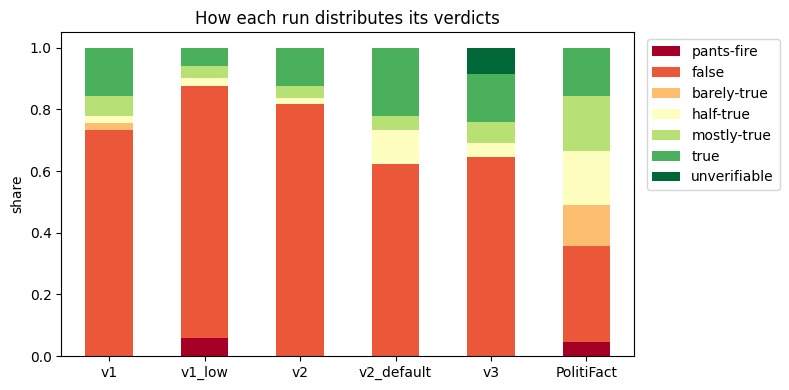

In [7]:
share = pd.DataFrame({v: f["verdict"].value_counts(normalize=True) for v, f in flats.items()})
share["PolitiFact"] = flats["v1"]["gold_label"].value_counts(normalize=True)
share = share.reindex(ev.LABELS + ["unverifiable"]).fillna(0)
ax = share.T.plot.bar(stacked=True, figsize=(8, 4), rot=0, colormap="RdYlGn",
                      title="How each run distributes its verdicts")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left"); ax.set_ylabel("share")
plt.tight_layout(); plt.show()

---
## Decision: apply the rule

In [8]:
cand = table.T.copy()
eligible = cand[cand["failure rate"] <= 0.05]
print("Eligible runs (failure rate <= 5%):", list(eligible.index) or "none")
if eligible.empty:
    eligible = cand
    print("No run met the failure-rate bar, so all runs are considered.")

best_f1 = eligible["macro-F1 (binary)"].max()
close = eligible[eligible["macro-F1 (binary)"] >= best_f1 - 0.02].copy()
close["tok"] = close["median output tokens"].fillna(1e9)   # unknown token use ranks last
CHOSEN = close.sort_values(["tok", "macro-F1 (binary)"], ascending=[True, False]).index[0]

display(eligible[["failure rate", "macro-F1 (binary)", "accuracy (binary)", "median output tokens"]]
        .sort_values("macro-F1 (binary)", ascending=False))
print(f"\nCHOSEN configuration: {CHOSEN}")

Eligible runs (failure rate <= 5%): ['v1_low']


,failure rate,macro-F1 (binary),accuracy (binary),median output tokens
v1_low,0.0,0.391,0.454,179.0



CHOSEN configuration: v1_low


**Be honest about what this decision means.** It is made on 50 claims, so close calls may be
noise. The full run in Part 3 is the real test, because none of its scored claims were used to make the choice.

---
## Part 3: the full run

Runs the chosen configuration on the whole LIAR test set (1,267 claims). Already-finished claims are
skipped, so it can be stopped and restarted. If Groq's daily limit is reached, claims are logged as
`gave_up_after_retries`; just run this cell again the next day and it continues where it stopped.

**The scored set excludes** the 50 development claims and the 50 held-out claims, since both were used
to make decisions. What remains (about 1,167 claims) has never influenced the design.

In [13]:
if FULL_RUN:
    pipeline.run(provider=PROVIDER, limit=400, workers=WORKERS, version=CHOSEN)

FULL = pipeline.results_path(PROVIDER, CHOSEN)
used = set(pipeline.load_claims("data/test.tsv", 50)["id"]) | set(pipeline.load_claims("data/test.tsv", 50, holdout=True)["id"])
total = len(pipeline.load_claims("data/test.tsv", 100_000))
full_df = ev.load_results(FULL)
scored_df = full_df[~full_df["id"].isin(used)]
print(f"{len(full_df)} of {total} claims processed; {len(scored_df)} are in the untouched scoring set")
print(full_df["status"].value_counts().to_dict())

[v1_low] 204 cached, 196 to process with openai/gpt-oss-20b
  10/196  {'ok': 10}
  20/196  {'ok': 20}
  30/196  {'ok': 30}
  40/196  {'ok': 40}
  50/196  {'ok': 50}
  60/196  {'ok': 60}
  70/196  {'ok': 70}
  80/196  {'ok': 80}
  90/196  {'ok': 90}
  100/196  {'ok': 100}
  110/196  {'ok': 110}
  120/196  {'ok': 120}
  130/196  {'ok': 130}
  140/196  {'ok': 140}
  150/196  {'ok': 150}
  160/196  {'ok': 160}
  170/196  {'ok': 170}
  180/196  {'ok': 180}
  190/196  {'ok': 190}
  196/196  {'ok': 196}
Done. Results in results\groq_openai-gpt-oss-20b_v1_low.jsonl
400 of 1283 claims processed; 337 are in the untouched scoring set
{'ok': 400}


In [14]:
if len(scored_df) >= 200:
    scored = ev.flatten_ok(scored_df)
    final = pd.Series({**ev.health(scored_df), "median output tokens": tokens(scored_df), **ev.metrics(scored)},
                      name=f"{CHOSEN} on untouched claims")
    display(final.to_frame())
else:
    print("Run the full set first (set FULL_RUN = True). The final numbers appear here.")

,v1_low on untouched claims
claims,337.000
usable answers,337.000
failure rate,0.000
empty replies,0.000
rate-limited claims,98.000
median latency (s),3.530
mean tokens per call,465.000
median output tokens,178.000
accuracy (6-class),0.181
macro-F1 (6-class),0.095


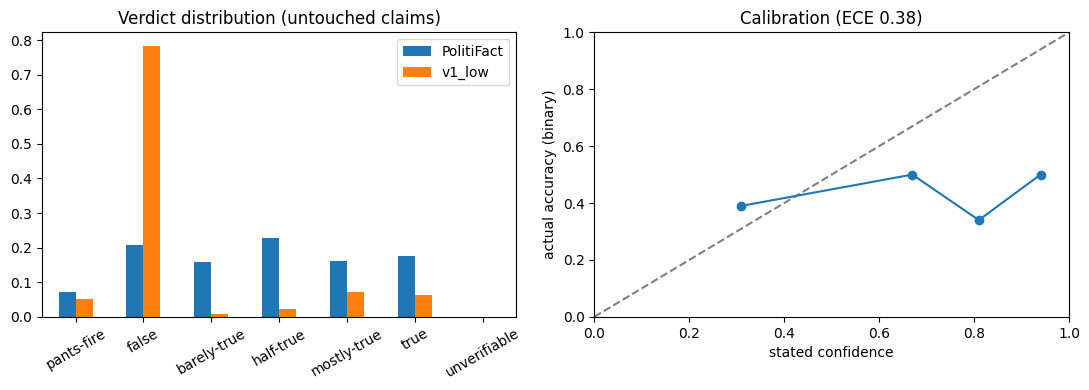

In [15]:
if len(scored_df) >= 200:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    d = pd.DataFrame({"PolitiFact": scored["gold_label"].value_counts(normalize=True),
                      CHOSEN: scored["verdict"].value_counts(normalize=True)}).reindex(ev.LABELS + ["unverifiable"]).fillna(0)
    d.plot.bar(ax=axes[0], rot=30, title="Verdict distribution (untouched claims)")
    t = ev.calibration_table(scored)
    axes[1].plot([0, 1], [0, 1], "--", color="grey")
    axes[1].plot(t["mean_confidence"], t["accuracy"], "o-")
    axes[1].set(xlim=(0, 1), ylim=(0, 1), xlabel="stated confidence", ylabel="actual accuracy (binary)",
                title=f"Calibration (ECE {ev.ece(scored):.2f})")
    plt.tight_layout(); plt.show()

In [16]:
# Accuracy by topic: where does the model do best and worst? (topics with 20+ claims)
if len(scored_df) >= 200:
    raw = pipeline.load_claims("data/test.tsv", 100_000)[["id", "subject"]]
    by = scored.merge(raw, on="id")
    by["subject"] = by["subject"].str.split(",").str[0]
    topic = by.groupby("subject").agg(claims=("id", "count"), accuracy_binary=("correct_bin", "mean"),
                                      share_false=("verdict", lambda s: (s == "false").mean()))
    display(topic[topic["claims"] >= 20].sort_values("accuracy_binary").round(2))

,claims,accuracy_binary,share_false
subject,,,
education,20,0.25,0.75
elections,24,0.38,0.92
health-care,27,0.59,0.81
candidates-biography,24,0.62,0.83


---
## Conclusions (fill in from the tables)

**Ablation**
- Reasoning effort and accuracy:
- Reasoning effort and empty replies:
- Abstention:
- Chosen configuration and why:

**Final result on untouched claims**
- Binary accuracy and macro-F1 vs baseline:
- Bias toward "false":
- Calibration:
- Cost (tokens per claim) and failure rate:

**Limitations:** one model; a single run per configuration at temperature 0; 50-claim ablations;
LIAR claims (2007–2016) are likely in the model's training data; no access to sources, so verdicts
come from the model's memory alone.